# [Lab Session 3](fourier.ipynb)


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [3]:
cell_img = plt.imread('data/cells.png')
plt.imshow(cell_img)
cell_resize = resize(cell_img,(256,256))
plt.show()

<Figure size 640x480 with 1 Axes>

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [4]:
cell_ft= np.fft.fft2(cell_resize)
cell_ft.dtype

dtype('complex128')

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [5]:
amplitude= np.abs(cell_ft)
phase= np.angle(cell_ft)

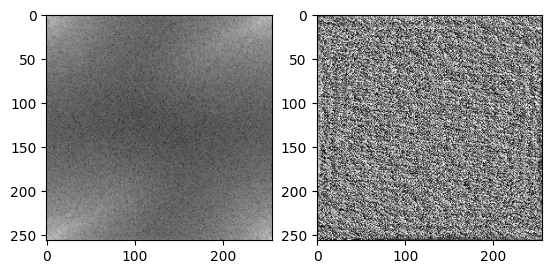

In [6]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

log_amplitude=np.log1p(amplitude)

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


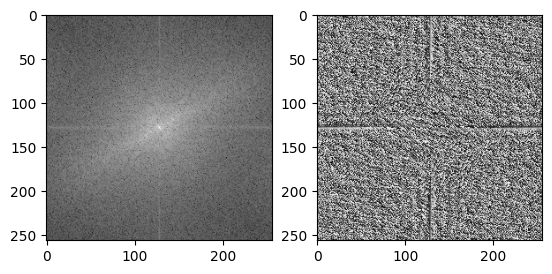

In [7]:
cell_ft_shift=np.fft.fftshift(cell_ft)
amplitude_cell= np.abs(cell_ft_shift)
phase_cell= np.angle(cell_ft_shift)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_cell), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_cell, 'gray')



**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


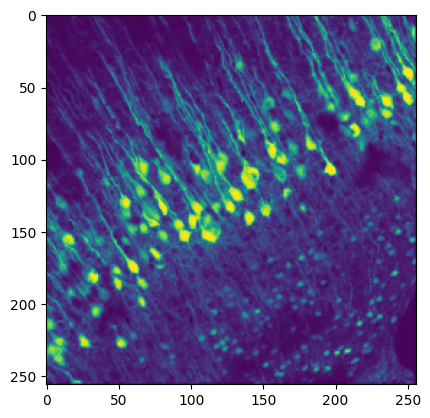

In [8]:
cell1= np.fft.ifftshift(cell_ft_shift)
cell= np.fft.ifft2(cell1)
plt.imshow(np.abs(cell))

---


**[Task 2 (a).]()** Load the brain MR image.


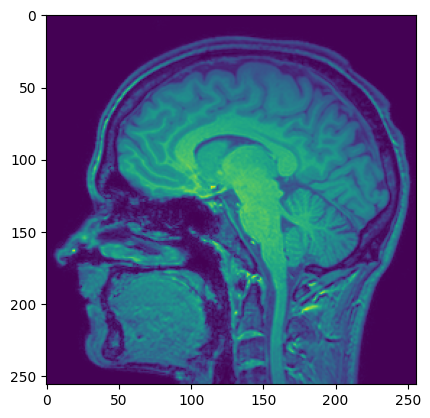

In [9]:
brain=plt.imread('data/brain_mri.png')
plt.imshow(brain)

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


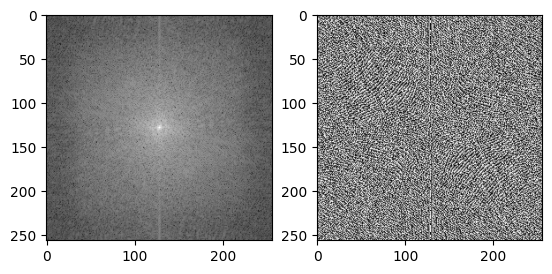

In [10]:
brain_ft=np.fft.fft2(brain)
brain_shift=np.fft.fftshift(brain_ft)
amplitude_brain= np.abs(brain_shift)
phase_brain= np.angle(brain_shift)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_brain, 'gray')


In [11]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


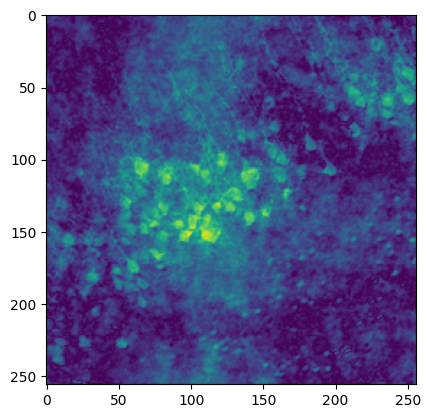

In [12]:

merged = to_complex_array(amplitude_brain, phase_cell)
merged1= np.fft.ifftshift(merged)
brain_cell= np.fft.ifft2(merged1)
plt.imshow(np.abs(brain_cell))


**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


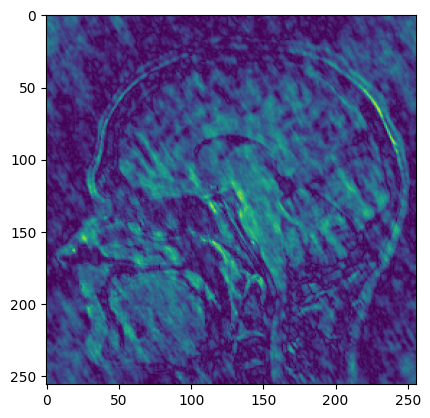

In [13]:
merged_rev = to_complex_array(amplitude_cell, phase_brain)
merged1_rev= np.fft.ifftshift(merged_rev)
cell_brain= np.fft.ifft2(merged1_rev)
plt.imshow(np.abs(cell_brain))

#conclusion : the phase holds more information


---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [14]:
filter_window_size = 50
mask= np.zeros(cell.shape)
# jetzt möchte ich ein fenster mit 1sen einsetzen in die mitte des ganzen

start_x = ((cell.shape[0]) - filter_window_size) // 2
end_x = start_x + filter_window_size

start_y = ((cell.shape[1]) - filter_window_size) // 2
end_y = start_y + filter_window_size


mask[start_x:end_x,start_y:end_y]=1

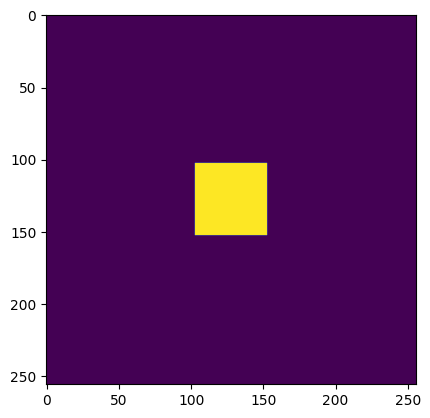

In [15]:
plt.imshow(mask)

**[Task 3 (b).]()** Create a highpass filter maks.


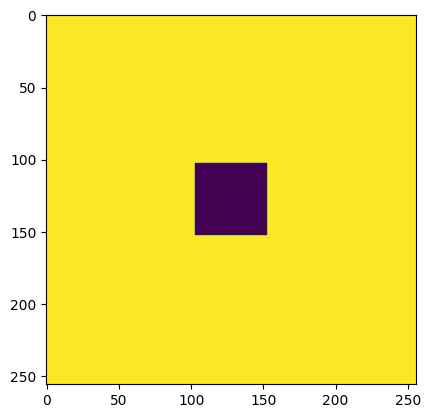

In [16]:
highmask = 1-mask
plt.imshow(highmask)

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


/tmp/ipykernel_3847/2012079177.py:8: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(amplitude_filtered_low), 'gray')
/tmp/ipykernel_3847/2012079177.py:11: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(amplitude_filtered_high), 'gray')


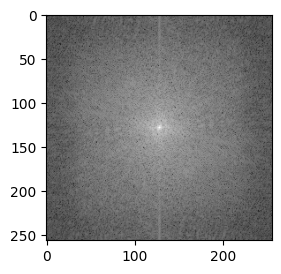

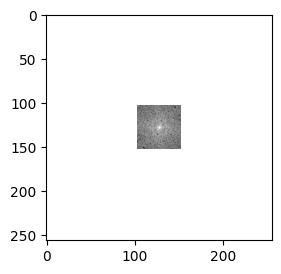

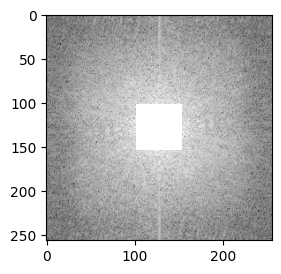

In [17]:
amplitude_filtered_low= amplitude_brain * mask
amplitude_filtered_high = amplitude_brain * highmask
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain), 'gray')
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_filtered_low), 'gray')
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_filtered_high), 'gray')

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


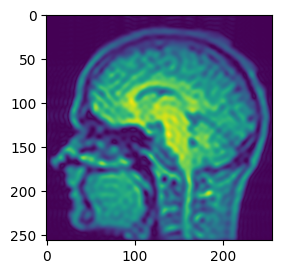

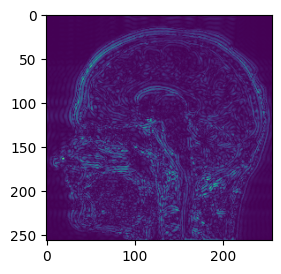

In [18]:
plt.figure()
plt.subplot(1, 2, 1)
merged_low = to_complex_array(amplitude_filtered_low, phase_brain)
merged1_low= np.fft.ifftshift(merged_low)
cell_brain_low= np.fft.ifft2(merged1_low)
plt.imshow(np.abs(cell_brain_low))

plt.figure()
plt.subplot(1, 2, 1)
merged_high = to_complex_array(amplitude_filtered_high, phase_brain)
merged1_high= np.fft.ifftshift(merged_high)
cell_brain_high= np.fft.ifft2(merged1_high)
plt.imshow(np.abs(cell_brain_high))


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [19]:
def dtf (img):
    result=np.zeros(img.shape,dtype=complex)
    M,N=img.shape
    for u in range(M):
        for v in range  (N):
            for x in range (M):
                for y in range (N):
                    result[u,v]+=img[x,y]*np.exp(-2j*np.pi*(u*x/M+v*y/N))
    return result/(M*N)

            

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [20]:
def idtf (img):
    result=np.zeros(img.shape,dtype=complex)
    M,N=img.shape
    for u in range(M):
        for v in range  (N):
            for x in range (M):
                for y in range (N):
                    result[u,v]+=img[x,y]*np.exp(2j*np.pi*(u*x/M+v*y/N))
    return result

Due to high computational costs, we need to resize the image.


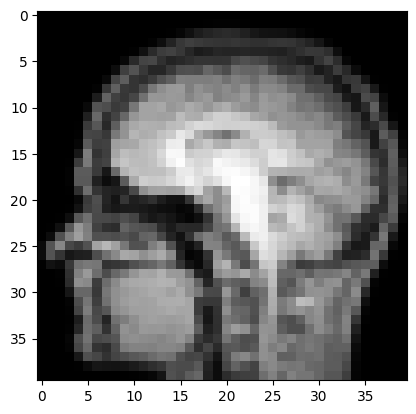

In [21]:
test_img = resize(brain, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


[[ 0.23930975+0.00000000e+00j -0.07902042+1.35039270e-02j
  -0.0293801 -8.40757442e-03j ... -0.00168727-6.82545817e-03j
  -0.0293801 +8.40757442e-03j -0.07902042-1.35039270e-02j]
 [-0.06501005+9.89234175e-04j  0.01532717+1.58226256e-03j
   0.01209535-7.33450384e-03j ...  0.005973  +5.12406457e-03j
  -0.01001424-1.52316941e-02j  0.01549852+2.38259364e-02j]
 [-0.02102203+3.41173006e-02j  0.01306517+1.31872980e-03j
   0.00038974-1.36106456e-02j ... -0.0041425 +1.79604314e-03j
   0.0201361 -4.59228613e-03j  0.0011157 -2.85754336e-02j]
 ...
 [-0.00222803-9.90004839e-04j  0.01074366-3.14743305e-03j
  -0.01147391-1.78253215e-03j ...  0.00105571-1.83702441e-03j
   0.00851254-8.62847239e-05j -0.00345942+4.93242583e-03j]
 [-0.02102203-3.41173006e-02j  0.0011157 +2.85754336e-02j
   0.0201361 +4.59228613e-03j ... -0.00159039-1.32590434e-03j
   0.00038974+1.36106456e-02j  0.01306517-1.31872980e-03j]
 [-0.06501005-9.89234175e-04j  0.01549852-2.38259364e-02j
  -0.01001424+1.52316941e-02j ...  0.00628

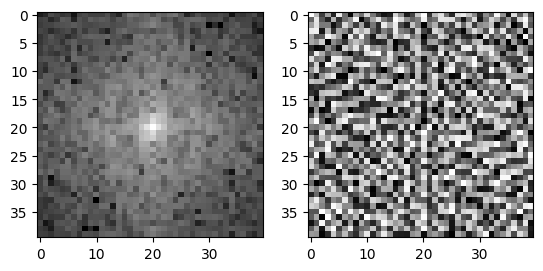

In [22]:
brain_test= dtf(test_img)
print(brain_test)

brain_shift=np.fft.fftshift(brain_test)
amplitude_brain= np.abs(brain_shift)
phase_brain= np.angle(brain_shift)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_brain, 'gray')


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


[[ 0.23930975+0.00000000e+00j -0.07902042+1.35039270e-02j
  -0.0293801 -8.40757442e-03j ... -0.00168727-6.82545817e-03j
  -0.0293801 +8.40757442e-03j -0.07902042-1.35039270e-02j]
 [-0.06501005+9.89234175e-04j  0.01532717+1.58226256e-03j
   0.01209535-7.33450384e-03j ...  0.005973  +5.12406457e-03j
  -0.01001424-1.52316941e-02j  0.01549852+2.38259364e-02j]
 [-0.02102203+3.41173006e-02j  0.01306517+1.31872980e-03j
   0.00038974-1.36106456e-02j ... -0.0041425 +1.79604314e-03j
   0.0201361 -4.59228613e-03j  0.0011157 -2.85754336e-02j]
 ...
 [-0.00222803-9.90004839e-04j  0.01074366-3.14743305e-03j
  -0.01147391-1.78253215e-03j ...  0.00105571-1.83702441e-03j
   0.00851254-8.62847239e-05j -0.00345942+4.93242583e-03j]
 [-0.02102203-3.41173006e-02j  0.0011157 +2.85754336e-02j
   0.0201361 +4.59228613e-03j ... -0.00159039-1.32590434e-03j
   0.00038974+1.36106456e-02j  0.01306517-1.31872980e-03j]
 [-0.06501005-9.89234175e-04j  0.01549852-2.38259364e-02j
  -0.01001424+1.52316941e-02j ...  0.00628

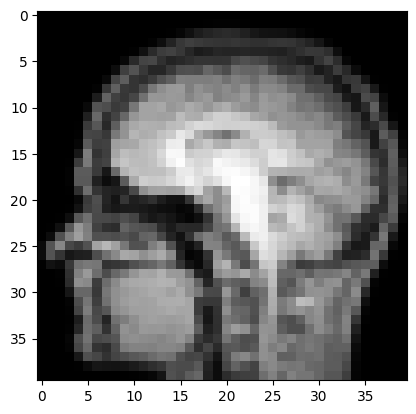

In [23]:
braini= np.fft.ifftshift(brain_shift)

brainio= idtf(braini)
print(brain_test)

plt.imshow(np.abs(brainio))
plt.imshow(np.abs(brainio), cmap='gray')



**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [24]:
brain_test=dtf(test_img)
brain_fft= np.fft.fft2(test_img,norm= 'forward')
print(np.allclose(brain_test, brain_fft))

True


**[Task 4 (f).]()** Round the arrays and compare them again.


In [25]:
mean_difference= np.mean(np.abs(brain_test-brain_fft))
print(mean_difference)
gerundet= np.round(brain_test,5)
gerundet2 = np.round(brain_fft,5)
print((gerundet==gerundet2).all())

7.541097048883874e-17
True


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)


In [26]:
%timeit brain_test=dtf(test_img)
%timeit brain_fft= np.fft.fft2(test_img,norm= 'forward')

5.23 s ± 39.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
38.1 μs ± 11.9 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
